# Compare the six-class benchmark

This CPU-only notebook reads the five source-wise result pairs listed in the [historical manifest](../../configs/experiments/public_benchmark.json). It writes new summary tables and charts to `.local/public_benchmark/`. The [historical tables](../../reports/public_benchmark/tables/) and [protocol](../../docs/benchmark_protocol.md) remain the reference for the recorded runs.

## Archived Historical Execution Evidence

The five detectors are compared below on the six-class benchmark using mAP50–95. The saved comparison table is summarized to four decimals from the verified evaluation CSV. Source-wise columns use held-out images from sources represented in training.

| Detector | Merged | DeepPCB | DsPCBSD | HRIPCB |
| --- | --- | --- | --- | --- |
| YOLOv11s | 0.5761 | 0.7538 | 0.4874 | 0.3060 |
| RT-DETR-L | 0.6595 | 0.8345 | 0.5399 | 0.5198 |
| Faster R-CNN | 0.5918 | 0.7773 | 0.5121 | 0.3919 |
| YOLOv11s-CBAMLite-BiFPNLite-P2 | 0.5764 | 0.7517 | 0.4721 | 0.3821 |
| PCBNet-RTDETR-HybridOpt | 0.6112 | 0.7596 | 0.5068 | 0.4731 |

The first saved PNG compares the merged test results. The second includes the merged set and the three source-specific subsets. They come from the historical comparison notebook, before its input-loading code was revised.

Original Kaggle notebook `notebooks/07_compare_sourcewise_benchmark_results.ipynb` in Git commit `4f3eb23`. Cell and output indices are zero-based. Table from cell 10, output 0. Figures from cell 12, output 1, and cell 14, output 1. [Source-wise CSV](../../reports/public_benchmark/tables/model_comparison_sourcewise_pivot.csv) · [Evaluation protocol](../../docs/benchmark_protocol.md)

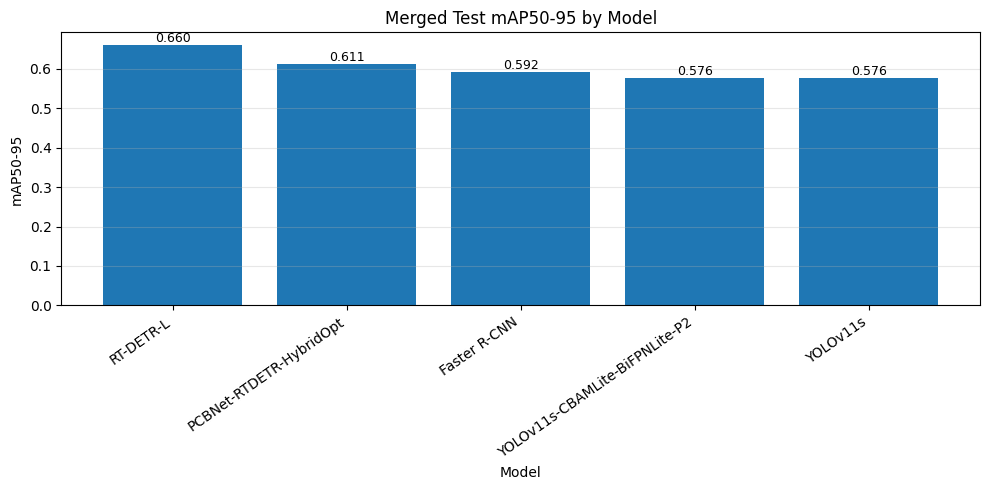

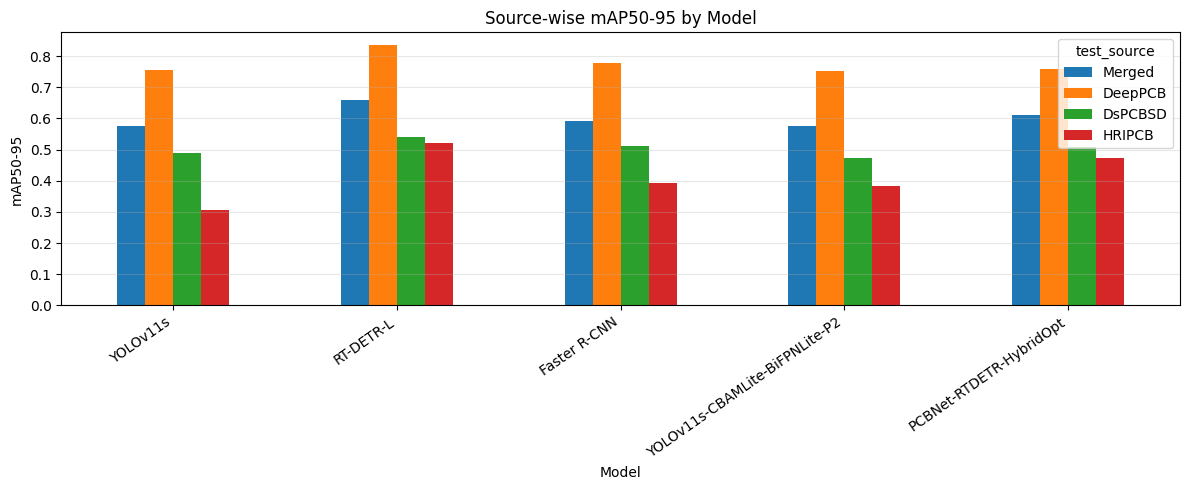

In [ ]:
# Display-only historical figures. See the source references above.

## 1. Imports and project paths

In [ ]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MANIFEST = Path("configs/experiments/public_benchmark.json")
PROJECT_ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / MANIFEST).is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from within the repository.")

experiments = json.loads((PROJECT_ROOT / MANIFEST).read_text(encoding="utf-8"))["experiments"]
OUTPUT_ROOT = PROJECT_ROOT / ".local" / "public_benchmark"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_ORDER = [
    "missing_hole",
    "mouse_bite",
    "open_circuit",
    "short",
    "spur",
    "spurious_copper",
]

SOURCE_ORDER = ["Merged", "DeepPCB", "DsPCBSD", "HRIPCB", "UNKNOWN"]

MODEL_ORDER = [item["display_name"] for item in experiments]

WEAK_CLASSES = ["spur", "mouse_bite", "short"]

## 2. Helper functions

In [ ]:
def standardize_metric_columns(df):
    rename_map = {
        "mAP50-95": "mAP50_95",
        "map50_95": "mAP50_95",
        "map50-95": "mAP50_95",
        "map50": "mAP50",
        "precision(B)": "precision",
        "recall(B)": "recall",
    }
    return df.rename(columns={c: rename_map.get(c, c) for c in df.columns})

def read_model_csv(path, model_name):
    df = standardize_metric_columns(pd.read_csv(path))
    df["source_file"] = path.name
    df["model_display_name"] = model_name
    return df


def sort_model_source(df):
    df = df.copy()

    if "model_display_name" in df.columns:
        df["model_order"] = df["model_display_name"].apply(
            lambda x: MODEL_ORDER.index(x) if x in MODEL_ORDER else len(MODEL_ORDER)
        )

    if "test_source" in df.columns:
        df["source_order"] = df["test_source"].apply(
            lambda x: SOURCE_ORDER.index(x) if x in SOURCE_ORDER else len(SOURCE_ORDER)
        )

    sort_cols = [c for c in ["model_order", "source_order", "class_id"] if c in df.columns]
    if sort_cols:
        df = df.sort_values(sort_cols)

    return df.drop(columns=[c for c in ["model_order", "source_order"] if c in df.columns])

def save_table(df, name, index=False):
    out = TABLE_DIR / name
    df.to_csv(out, index=index)
    print("Saved:", out)
    return out

def save_figure(name):
    out = FIGURE_DIR / name
    plt.tight_layout()
    plt.savefig(out, dpi=180, bbox_inches="tight")
    print("Saved:", out)
    plt.show()
    return out

def format_display_df(df, digits=4):
    out = df.copy()
    num_cols = out.select_dtypes(include=[np.number]).columns
    for c in num_cols:
        out[c] = out[c].round(digits)
    return out

## 3. Load all source-wise result CSV files

In [ ]:
summary_frames = []
per_class_frames = []
for item in experiments:
    summary_path = PROJECT_ROOT / item["results_file"]
    per_class_path = summary_path.with_name(
        summary_path.name.replace("_summary_metrics.csv", "_per_class_map.csv")
    )
    summary_frames.append(read_model_csv(summary_path, item["display_name"]))
    per_class_frames.append(read_model_csv(per_class_path, item["display_name"]))

summary_df = sort_model_source(pd.concat(summary_frames, ignore_index=True))
per_class_df = sort_model_source(pd.concat(per_class_frames, ignore_index=True))

if summary_df.duplicated(["model_display_name", "test_source"]).any():
    raise ValueError("Duplicate model and test source in benchmark inputs.")
if per_class_df.duplicated(["model_display_name", "test_source", "class_id"]).any():
    raise ValueError("Duplicate model, test source, and class in benchmark inputs.")

display(format_display_df(summary_df))
save_table(summary_df, "all_models_sourcewise_summary_metrics.csv")
save_table(per_class_df, "all_models_sourcewise_per_class_map.csv")

## 4. Overall merged-test model comparison

In [ ]:
metric_cols = [
    "precision",
    "recall",
    "f1",
    "mAP50",
    "mAP50_95",
    "inference_ms_per_image",
    "FPS",
]

available_metric_cols = [c for c in metric_cols if c in summary_df.columns]

merged_comparison_df = (
    summary_df[summary_df["test_source"] == "Merged"]
    [["model_display_name", "test_source", *available_metric_cols]]
    .drop_duplicates(subset=["model_display_name", "test_source"])
    .copy()
)

merged_comparison_df["model_order"] = merged_comparison_df["model_display_name"].apply(
    lambda x: MODEL_ORDER.index(x) if x in MODEL_ORDER else len(MODEL_ORDER)
)
merged_comparison_df = merged_comparison_df.sort_values("model_order").drop(columns="model_order")

display(format_display_df(merged_comparison_df))
save_table(merged_comparison_df, "model_comparison_merged_test.csv")

best_row = merged_comparison_df.sort_values("mAP50_95", ascending=False).iloc[0]
print(
    "Best merged-test model by mAP50-95:",
    best_row["model_display_name"],
    "| mAP50-95 =",
    round(float(best_row["mAP50_95"]), 4),
)

## 5. Source-wise overall comparison

In [ ]:
sourcewise_pivot = summary_df.pivot_table(
    index="model_display_name",
    columns="test_source",
    values="mAP50_95",
    aggfunc="first",
)

sourcewise_pivot = sourcewise_pivot.reindex(
    index=[m for m in MODEL_ORDER if m in sourcewise_pivot.index],
    columns=[s for s in SOURCE_ORDER if s in sourcewise_pivot.columns],
)

source_cols = [c for c in ["DeepPCB", "DsPCBSD", "HRIPCB"] if c in sourcewise_pivot.columns]

sourcewise_pivot["mean_source_mAP50_95"] = sourcewise_pivot[source_cols].mean(axis=1)
sourcewise_pivot["std_source_mAP50_95"] = sourcewise_pivot[source_cols].std(axis=1)
sourcewise_pivot["min_source_mAP50_95"] = sourcewise_pivot[source_cols].min(axis=1)

sourcewise_pivot = sourcewise_pivot.reset_index()

display(format_display_df(sourcewise_pivot))
save_table(sourcewise_pivot, "model_comparison_sourcewise_pivot.csv")

## 6. Plot: mAP50-95 on merged test by model

In [ ]:
plot_df = merged_comparison_df.copy()
plot_df = plot_df.sort_values("mAP50_95", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(plot_df["model_display_name"], plot_df["mAP50_95"])
plt.title("Merged Test mAP50-95 by Model")
plt.xlabel("Model")
plt.ylabel("mAP50-95")
plt.xticks(rotation=35, ha="right")
plt.grid(axis="y", alpha=0.3)

for i, v in enumerate(plot_df["mAP50_95"]):
    plt.text(i, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

save_figure("model_comparison_merged_map50_95.png")

## 7. Plot: source-wise mAP50-95 by model

In [ ]:
plot_sources = [s for s in ["Merged", "DeepPCB", "DsPCBSD", "HRIPCB"] if s in summary_df["test_source"].unique()]

plot_pivot = summary_df.pivot_table(
    index="model_display_name",
    columns="test_source",
    values="mAP50_95",
    aggfunc="first",
)

plot_pivot = plot_pivot.reindex(index=[m for m in MODEL_ORDER if m in plot_pivot.index])
plot_pivot = plot_pivot[plot_sources]

ax = plot_pivot.plot(kind="bar", figsize=(12, 5))
ax.set_title("Source-wise mAP50-95 by Model")
ax.set_xlabel("Model")
ax.set_ylabel("mAP50-95")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")

save_figure("model_comparison_sourcewise_map50_95.png")

## 8. Per-class comparison on merged test

In [ ]:
merged_per_class_df = per_class_df[per_class_df["test_source"] == "Merged"].copy()

per_class_pivot = merged_per_class_df.pivot_table(
    index="class_name",
    columns="model_display_name",
    values="mAP50_95",
    aggfunc="first",
)

per_class_pivot = per_class_pivot.reindex(
    index=[c for c in CLASS_ORDER if c in per_class_pivot.index],
    columns=[m for m in MODEL_ORDER if m in per_class_pivot.columns],
)

display(format_display_df(per_class_pivot.reset_index()))

per_class_pivot.reset_index().to_csv(TABLE_DIR / "per_class_comparison_merged_test_pivot.csv", index=False)
print("Saved:", TABLE_DIR / "per_class_comparison_merged_test_pivot.csv")

class_difficulty_df = per_class_pivot.copy()
class_difficulty_df["mean_mAP50_95"] = class_difficulty_df.mean(axis=1)
class_difficulty_df["min_mAP50_95"] = class_difficulty_df.min(axis=1)
class_difficulty_df["max_mAP50_95"] = class_difficulty_df.max(axis=1)
class_difficulty_df = class_difficulty_df.reset_index().sort_values("mean_mAP50_95")

display(format_display_df(class_difficulty_df))
save_table(class_difficulty_df, "class_difficulty_summary_merged_test.csv")

## 9. Plot: per-class mAP50-95 on merged test

In [ ]:
ax = per_class_pivot.plot(kind="bar", figsize=(13, 5))
ax.set_title("Per-class mAP50-95 on Merged Test")
ax.set_xlabel("Class")
ax.set_ylabel("mAP50-95")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=45, ha="right")

save_figure("per_class_comparison_merged_test_map50_95.png")

## 10. Weak-class focus: spur, mouse_bite, short

In [ ]:
weak_class_df = per_class_df[per_class_df["class_name"].isin(WEAK_CLASSES)].copy()
weak_class_df = sort_model_source(weak_class_df)

display(format_display_df(weak_class_df))
save_table(weak_class_df, "weak_class_focus_sourcewise.csv")

weak_merged_pivot = weak_class_df[weak_class_df["test_source"] == "Merged"].pivot_table(
    index="class_name",
    columns="model_display_name",
    values="mAP50_95",
    aggfunc="first",
)

weak_merged_pivot = weak_merged_pivot.reindex(
    index=[c for c in WEAK_CLASSES if c in weak_merged_pivot.index],
    columns=[m for m in MODEL_ORDER if m in weak_merged_pivot.columns],
)

display(format_display_df(weak_merged_pivot.reset_index()))

weak_merged_pivot.reset_index().to_csv(TABLE_DIR / "weak_class_comparison_merged_test_pivot.csv", index=False)
print("Saved:", TABLE_DIR / "weak_class_comparison_merged_test_pivot.csv")

## 11. Plot: weak classes on merged test

In [ ]:
ax = weak_merged_pivot.plot(kind="bar", figsize=(11, 5))
ax.set_title("Weak-class mAP50-95 on Merged Test")
ax.set_xlabel("Class")
ax.set_ylabel("mAP50-95")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)

save_figure("weak_class_comparison_merged_test_map50_95.png")

## 12. Source difficulty analysis

In [ ]:
source_difficulty_df = summary_df.pivot_table(
    index="test_source",
    values="mAP50_95",
    aggfunc=["mean", "std", "min", "max"],
)

source_difficulty_df.columns = [
    "mean_mAP50_95",
    "std_mAP50_95",
    "min_mAP50_95",
    "max_mAP50_95",
]

source_difficulty_df = source_difficulty_df.reindex([s for s in SOURCE_ORDER if s in source_difficulty_df.index])
source_difficulty_df = source_difficulty_df.reset_index()

display(format_display_df(source_difficulty_df))
save_table(source_difficulty_df, "source_difficulty_summary.csv")

hardest_source = source_difficulty_df.sort_values("mean_mAP50_95").iloc[0]
print(
    "Hardest source by mean mAP50-95:",
    hardest_source["test_source"],
    "| mean mAP50-95 =",
    round(float(hardest_source["mean_mAP50_95"]), 4),
)

## 13. Best model per source and per class

In [ ]:
best_model_per_source_df = (
    summary_df.sort_values("mAP50_95", ascending=False)
    .groupby("test_source", as_index=False)
    .first()
    [["test_source", "model_display_name", "mAP50_95", "mAP50", "precision", "recall"]]
)

best_model_per_source_df["source_order"] = best_model_per_source_df["test_source"].apply(
    lambda x: SOURCE_ORDER.index(x) if x in SOURCE_ORDER else len(SOURCE_ORDER)
)
best_model_per_source_df = best_model_per_source_df.sort_values("source_order").drop(columns="source_order")

display(format_display_df(best_model_per_source_df))
save_table(best_model_per_source_df, "best_model_per_source.csv")

best_model_per_class_merged_df = (
    merged_per_class_df.sort_values("mAP50_95", ascending=False)
    .groupby("class_name", as_index=False)
    .first()
    [["class_name", "model_display_name", "mAP50_95"]]
)

best_model_per_class_merged_df["class_order"] = best_model_per_class_merged_df["class_name"].apply(
    lambda x: CLASS_ORDER.index(x) if x in CLASS_ORDER else len(CLASS_ORDER)
)
best_model_per_class_merged_df = best_model_per_class_merged_df.sort_values("class_order").drop(columns="class_order")

display(format_display_df(best_model_per_class_merged_df))
save_table(best_model_per_class_merged_df, "best_model_per_class_merged_test.csv")